# Problem Analysis Workshop C — Transformation/Linear Regression

**Course:** PROG8431 — Data Analysis, Mathematics, Modeling and Algorithms

**Team Members:**
- Ubaid Ullah — 9110715
- Rangeetha — 9081357
- Koushik Balne — 9087547






## Problem Analysis Statement

Nitrogen is the most widely used fertilizer nutrient and often a crop's largest fertilizer cost, yet the soil nitrogen level crops need varies widely. In our data, average N ranges from about 19 for lentil and pomegranate to about 118 for cotton. If we can't explain these differences, fertilizer has to be planned crop by crop from experience, which risks over-applying an expensive input.

**Problem:** we do not know which crop characteristics and growing conditions explain the soil nitrogen (N) level at which a crop grows well, or how accurately N can be predicted for a new field.

**Objective:** identify the variables that explain N and measure how well a regression model predicts it on unseen data.

**Scope:** Our Crop Analyzer project data , augmented with outside sources, analysed with transformations, validation and regression

### Approach

- **Data:** the Crop Recommendation dataset (2,200 rows, 22 crops × 100) with soil nutrients (N, P, K), temperature, humidity, pH and rainfall.
- **Augmentation:** FAO EcoCrop growing requirements and Statistics Canada crop area and value, joined on crop name, giving a study file of 25+ usable variables.
- **Method:** an 80/20 train/test split, two simple linear regressions, then a multiple linear regression narrowed down with backward selection.

## How Transformations and Regression Help the Project

Together they take the Crop Analyzer from describing the data (what each crop's conditions look like) to prediction (how much nitrogen a crop will need, and why). That is the step from descriptive to predictive analysis in the class slides.

| Technique | What it does | How it helps our project |
| --- | --- | --- |
| Box-Cox / Tukey's ladder | Reshapes skewed variables toward a normal distribution | K (skew 2.4), P, rainfall and humidity are skewed; apple and grapes sit near K = 200. Transforming them gives straighter relationships with N and less pull from those extreme crops. |
| log(x + 1) | Compresses values that are mostly zero | The Canadian area and value columns can enter the model even though most crops aren't grown in Canada. |
| Dummy and ordinal coding | Turns categories into numbers a regression can use | Crop category, life form and pH class become predictors, which is how crop traits enter the model. |
| Simple linear regression | Measures one predictor's effect on N | Already shows legumes grow at about 36 N less than other crops, with a clear biological reason. |
| Multiple linear regression + backward selection | Combines several predictors, keeping only those that contribute | Explains N from crop traits and field conditions together, using the simplest model that fits. |
| Train/test validation (RMSE) | Measures error on fields the model has not seen | Tells us how far off a prediction for a new field is likely to be (about 34 N for the best single predictor), so we know how much to trust it. |

The result is a model the team can use for fertilizer planning, and a short list of what drives a crop's nitrogen level for later stages of the project.

## 1. Environment Setup

These libraries must be installed in your Python kernel before the notebook is run

In [ ]:
%pip install ipython
%pip install seaborn
%pip install statsmodels
%pip install scikit-learn
%pip install scipy

#### Coding Set Up

Start by clearing all output and workspace.

In [3]:
# Clear plots
import matplotlib.pyplot as plt
plt.close('all')

# Clear console
from IPython.display import clear_output
clear_output()

# Clean workspace
%reset -f

import pandas as pd
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

Import Necessary Packages

In [4]:
import os
import io
import re
import zipfile
import urllib.request

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency, spearmanr, boxcox
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import statsmodels.api as sm
import statsmodels.formula.api as smf

from IPython.display import display

#### Configuration

All file locations, download links and fixed settings live in this one cell.

* `CROP_FILE` – our project dataset. Put `Crop_recommendation.csv` in the same folder as this notebook (or change the path).
* External files are downloaded **once** into `data/` and re-used on later runs. If your network blocks a download, download the file manually from the URL shown and save it in `data/` under the file name shown — the notebook will then use the local copy.
* `RANDOM_STATE = 6174` matches the class MLR demo so the split is reproducible.

In [5]:
# Set up number displays
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 80)
np.set_printoptions(suppress=True)

CROP_FILE = "Crop_recommendation.csv"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

SOURCES = {
    # FAO EcoCrop database (full copy published in the OpenCLIM/ecocrop GitHub repository)
    "ecocrop": ("https://raw.githubusercontent.com/OpenCLIM/ecocrop/main/EcoCrop_DB.csv",
                "EcoCrop_DB.csv"),
    # Statistics Canada 32-10-0359-01: area, yield, production, price and farm value of principal field crops
    "statcan_field": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100359-eng.zip",
                      "32100359-eng.zip"),
    # Statistics Canada 32-10-0364-01: area, production and farm gate value of marketed fruits
    "statcan_fruit": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100364-eng.zip",
                      "32100364-eng.zip"),
    # Statistics Canada 32-10-0365-01: area, production and farm gate value of marketed vegetables (melons)
    "statcan_veg": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100365-eng.zip",
                    "32100365-eng.zip"),
}

STATCAN_YEARS = 5          # average of the most recent 5 years
RANDOM_STATE = 6174        # random seed for reproducibility
TEST_SIZE = 0.20           # 80/20 split, as in the class demo
ALPHA = 0.05               # significance level for all tests


def get_source(key):
    # Return the local path of a source file, downloading it on first use.
    url, fname = SOURCES[key]
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f"Downloading {fname} ...")
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=120) as r, open(path, "wb") as f:
                f.write(r.read())
        except Exception as e:
            raise RuntimeError(
                f"Could not download {url}\n({e})\n"
                f"Download it manually and save it as {path}, then re-run this cell."
            )
    return path

## 2. Data Augmentation

### 2.1 Primary dataset – Crop Recommendation

In [6]:
crop = pd.read_csv(CROP_FILE)

print("Original Crop Structure:")
crop.info()

# Consistent, short names (same idea as the rename step in the class demos)
crop.columns = [c.strip() for c in crop.columns]
crop = crop.rename(columns={"temperature": "temp", "humidity": "humid", "rainfall": "rain"})
crop["label"] = crop["label"].str.strip().str.lower()

print("\nRenamed Crop Structure:")
crop.info()

print("\nRows per crop:")
print(crop["label"].value_counts().sort_index())
print("\nMissing values per column:")
print(crop.isna().sum())

Original Crop Structure:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB

Renamed Crop Structure:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   N       2200 non-null   int64  
 1   P       2200 non-null   int64  
 2   K       2200 non-null   int64  
 3   temp    2200 non-null   float64
 4   humid   2200 non-null   float64
 5   ph      2200 non

### 2.2 External source 1 – FAO EcoCrop (crop environmental requirements)

For each of our 22 crops we pull FAO's published growing requirements: optimal and absolute temperature (°C), optimal and absolute annual rainfall (mm), optimal and absolute soil pH, crop cycle length (days), life form and crop category. Crops are matched by **scientific name**, which is unambiguous, rather than by common name.

In [7]:
ECOCROP_NAMES = {
    "rice":        ["Oryza sativa"],
    "maize":       ["Zea mays"],
    "chickpea":    ["Cicer arietinum"],
    "kidneybeans": ["Phaseolus vulgaris"],
    "pigeonpeas":  ["Cajanus cajan"],
    "mothbeans":   ["Vigna aconitifolia"],
    "mungbean":    ["Vigna radiata"],
    "blackgram":   ["Vigna mungo"],
    "lentil":      ["Lens culinaris", "Lens esculenta"],
    "pomegranate": ["Punica granatum"],
    "banana":      ["Musa acuminata", "Musa x paradisiaca", "Musa paradisiaca", "Musa"],
    "mango":       ["Mangifera indica"],
    "grapes":      ["Vitis vinifera"],
    "watermelon":  ["Citrullus lanatus"],
    "muskmelon":   ["Cucumis melo"],
    "apple":       ["Malus domestica", "Malus pumila", "Malus sylvestris", "Malus"],
    "orange":      ["Citrus sinensis"],
    "papaya":      ["Carica papaya"],
    "coconut":     ["Cocos nucifera"],
    "cotton":      ["Gossypium hirsutum"],
    "jute":        ["Corchorus capsularis", "Corchorus olitorius"],
    "coffee":      ["Coffea arabica"],
}

# EcoCrop field codes -> our names
ECO_NUMERIC = {
    "TOPMN": "eco_topt_min", "TOPMX": "eco_topt_max",   # optimal temperature (deg C)
    "TMIN":  "eco_tabs_min", "TMAX":  "eco_tabs_max",   # absolute temperature (deg C)
    "ROPMN": "eco_ropt_min", "ROPMX": "eco_ropt_max",   # optimal annual rainfall (mm)
    "RMIN":  "eco_rabs_min", "RMAX":  "eco_rabs_max",   # absolute annual rainfall (mm)
    "PHOPMN": "eco_phopt_min", "PHOPMX": "eco_phopt_max",  # optimal soil pH
    "PHMIN": "eco_phabs_min", "PHMAX": "eco_phabs_max",    # absolute soil pH
    "GMIN":  "eco_cycle_min", "GMAX":  "eco_cycle_max",    # crop cycle (days)
}
ECO_CATEGORICAL = {"LIFO": "life_form", "CAT": "eco_category"}

eco_raw = pd.read_csv(get_source("ecocrop"), encoding="latin-1", low_memory=False)
eco_raw.columns = [str(c).strip() for c in eco_raw.columns]
upper = {c.upper(): c for c in eco_raw.columns}

# Find the scientific-name column: the column that contains "Oryza sativa"
sci_col = next(c for c in eco_raw.columns
               if eco_raw[c].astype(str).str.contains("Oryza sativa", case=False, na=False).any())
eco_raw["_sci"] = (eco_raw[sci_col].astype(str).str.lower()
                   .str.replace(r"\s+", " ", regex=True).str.strip())

missing_cols = [k for k in list(ECO_NUMERIC) + list(ECO_CATEGORICAL) if k not in upper]
print("Scientific-name column:", sci_col)
print("EcoCrop fields not found (will be skipped):", missing_cols or "none")


def find_eco_row(names):
    for name in names:
        n = name.lower()
        exact = eco_raw[(eco_raw["_sci"] == n) | eco_raw["_sci"].str.startswith(n + " ")]
        if len(exact):
            return exact.iloc[0]
    return None


rows = []
for crop_name, names in ECOCROP_NAMES.items():
    r = find_eco_row(names)
    rec = {"label": crop_name, "eco_scientific_name": None if r is None else r[sci_col]}
    for code_, new in {**ECO_NUMERIC, **ECO_CATEGORICAL}.items():
        rec[new] = (r[upper[code_]] if (r is not None and code_ in upper) else np.nan)
    rows.append(rec)

eco = pd.DataFrame(rows)
for c in ECO_NUMERIC.values():
    if c in eco:
        eco[c] = pd.to_numeric(eco[c], errors="coerce")
for c in ECO_CATEGORICAL.values():
    # Some EcoCrop entries list several values ("herb, shrub"); keep the first (primary) one
    eco[c] = (eco[c].astype(str).str.split(r"[;,/]").str[0].str.strip().str.lower()
              .replace({"nan": np.nan, "": np.nan}))

# Keep only fields that actually have data
eco = eco.dropna(axis=1, how="all")

not_matched = eco.loc[eco["eco_scientific_name"].isna(), "label"].tolist()
if not_matched:
    raise ValueError(f"No EcoCrop record found for: {not_matched}. Check ECOCROP_NAMES.")

display(eco)
print("\nMissing EcoCrop values per field:")
print(eco.isna().sum())

Scientific-name column: ScientificName
EcoCrop fields not found (will be skipped): none


,label,eco_scientific_name,eco_topt_min,eco_topt_max,eco_tabs_min,eco_tabs_max,eco_ropt_min,eco_ropt_max,eco_rabs_min,eco_rabs_max,eco_phopt_min,eco_phopt_max,eco_phabs_min,eco_phabs_max,eco_cycle_min,eco_cycle_max,life_form,eco_category
0,rice,Oryza sativa,20.000000,30.000000,10.000000,36.000000,1500.000000,2000.000000,1000.000000,4000.000000,5.500000,7.000000,4.500000,9.000000,80.000000,180.000000,grass,cereals & pseudocereals
1,maize,Zea mays,18.000000,33.000000,10.000000,47.000000,600.000000,1200.000000,400.000000,1800.000000,5.000000,7.000000,4.500000,8.500000,65.000000,365.000000,NaN,NaN
2,chickpea,Cicer arietinum,15.000000,29.000000,7.000000,35.000000,600.000000,1000.000000,300.000000,1800.000000,6.000000,8.500000,4.700000,9.500000,90.000000,180.000000,herb,pulses (grain legumes)
3,kidneybeans,Phaseolus vulgaris,16.000000,25.000000,7.000000,32.000000,500.000000,2000.000000,300.000000,4300.000000,5.500000,7.500000,4.000000,9.000000,50.000000,270.000000,herb,pulses (grain legumes)
4,pigeonpeas,Cajanus cajan,18.000000,38.000000,10.000000,45.000000,600.000000,1500.000000,400.000000,4000.000000,5.000000,7.000000,4.500000,8.400000,90.000000,365.000000,shrub,vegetables
5,mothbeans,Vigna aconitifolia,24.000000,32.000000,13.000000,45.000000,500.000000,900.000000,400.000000,2500.000000,6.500000,7.500000,5.000000,8.000000,60.000000,90.000000,herb,pulses (grain legumes)
6,mungbean,Vigna radiata,21.000000,36.000000,8.000000,40.000000,650.000000,900.000000,500.000000,1250.000000,5.500000,6.200000,4.300000,8.300000,50.000000,120.000000,herb,pulses (grain legumes)
7,blackgram,Vigna mungo,22.000000,35.000000,8.000000,40.000000,650.000000,900.000000,530.000000,2430.000000,5.500000,6.500000,4.500000,7.500000,60.000000,130.000000,herb,pulses (grain legumes)
8,lentil,Lens culinaris,15.000000,29.000000,5.000000,32.000000,600.000000,1000.000000,250.000000,2500.000000,5.500000,7.500000,4.500000,8.200000,70.000000,240.000000,herb,pulses (grain legumes)
9,pomegranate,Punica granatum,23.000000,32.000000,8.000000,40.000000,900.000000,1200.000000,400.000000,4200.000000,6.500000,7.500000,5.800000,8.500000,180.000000,365.000000,shrub,fruits & nuts



Missing EcoCrop values per field:
label                  0
eco_scientific_name    0
eco_topt_min           0
eco_topt_max           0
eco_tabs_min           0
eco_tabs_max           0
eco_ropt_min           0
eco_ropt_max           0
eco_rabs_min           0
eco_rabs_max           0
eco_phopt_min          0
eco_phopt_max          0
eco_phabs_min          0
eco_phabs_max          0
eco_cycle_min          0
eco_cycle_max          0
life_form              1
eco_category           1
dtype: int64


### 2.3 External source 2 – Statistics Canada (is the crop grown commercially in Canada?)

Statistics Canada publishes harvested/cultivated area and farm value by crop. Only a few of our 22 crops are grown commercially in Canada, so for each crop we record:

* `grown_in_canada` – 1 if the crop appears in a StatCan table with a positive area, else 0
* `ca_area_ha` – average Canadian harvested/cultivated area over the last 5 years (0 if not grown)
* `ca_farm_value` – average Canadian farm (gate) value over the last 5 years, in dollars (0 if not grown)

A crop that is not grown in Canada genuinely has **0 hectares**, so 0 is a true value, not a missing value.

In [8]:
STATCAN_STD = {"REF_DATE", "GEO", "DGUID", "UOM", "UOM_ID", "SCALAR_FACTOR", "SCALAR_ID",
               "VECTOR", "COORDINATE", "VALUE", "STATUS", "SYMBOL", "TERMINATED", "DECIMALS"}
SCALE = {"units": 1, "tens": 10, "hundreds": 100, "thousands": 1e3, "millions": 1e6, "billions": 1e9}


def load_statcan(key):
    path = get_source(key)
    with zipfile.ZipFile(path) as z:
        name = next(n for n in z.namelist() if n.endswith(".csv") and "MetaData" not in n)
        df = pd.read_csv(z.open(name), low_memory=False)
    df = df[df["GEO"] == "Canada"].copy()
    df["VALUE"] = pd.to_numeric(df["VALUE"], errors="coerce")
    if "SCALAR_FACTOR" in df:
        mult = df["SCALAR_FACTOR"].astype(str).str.lower().str.strip().map(SCALE).fillna(1)
        df["VALUE"] = df["VALUE"] * mult
    df["YEAR"] = df["REF_DATE"].astype(str).str[:4].astype(int)
    return df


def statcan_avg(df, crop_patterns, metric_patterns):
    # Average of the last STATCAN_YEARS years for the first crop / metric category that matches.
    dims = [c for c in df.columns if c not in STATCAN_STD | {"YEAR"}]
    for cp in crop_patterns:
        for crop_dim in dims:
            crop_cats = sorted(c for c in df[crop_dim].dropna().unique()
                               if re.search(cp, str(c), flags=re.I))
            for cat in crop_cats:
                sub = df[df[crop_dim] == cat]
                for mp in metric_patterns:
                    for metric_dim in [d for d in dims if d != crop_dim]:
                        mcats = sorted(m for m in sub[metric_dim].dropna().unique()
                                       if re.search(mp, str(m), flags=re.I))
                        for mcat in mcats:
                            rows_ = sub[sub[metric_dim] == mcat].dropna(subset=["VALUE"])
                            # Same quantity published in acres and hectares -> keep hectares
                            uom = rows_["UOM"].astype(str) if "UOM" in rows_ else pd.Series(dtype=str)
                            if uom.str.contains("hectare", case=False).any() and uom.str.contains("acre", case=False).any():
                                rows_ = rows_[uom.str.contains("hectare", case=False)]
                            # Any other dimension: use its "total" level if there is one (avoid double counting)
                            other = [d for d in dims if d not in (crop_dim, metric_dim)]
                            if other:
                                is_total = rows_[other].astype(str).apply(
                                    lambda col: col.str.contains("total", case=False)).all(axis=1)
                                if is_total.any():
                                    rows_ = rows_[is_total]
                            s = rows_.groupby("YEAR")["VALUE"].sum().sort_index()
                            if len(s):
                                s = s.iloc[-STATCAN_YEARS:]
                                return s.mean(), f"{cat} | {mcat} | {s.index.min()}-{s.index.max()}"
    return 0.0, "not in table (not grown commercially)"


field = load_statcan("statcan_field")
fruit = load_statcan("statcan_fruit")
veg   = load_statcan("statcan_veg")

# Hectare versions first: the field-crop table publishes area in both acres and hectares
AREA_PAT  = [r"^harvested area.*hectare", r"cultivated area.*hectare", r"area.*hectare",
             r"^harvested area", r"cultivated area", r"bearing area", r"area harvested", r"area"]
VALUE_PAT = [r"total farm value", r"farm gate value", r"farm value", r"value"]

STATCAN_CROPS = {   # crop -> (table, crop-name patterns)
    "maize":       (field, [r"^corn for grain"]),
    "chickpea":    (field, [r"chick ?peas"]),
    "lentil":      (field, [r"^lentils"]),
    "kidneybeans": (field, [r"beans, all dry", r"dry.*beans", r"coloured beans"]),
    "apple":       (fruit, [r"^apples"]),
    "grapes":      (fruit, [r"^grapes"]),
    "watermelon":  (veg,   [r"watermelon"]),
    "muskmelon":   (veg,   [r"cantaloup", r"muskmelon", r"melons"]),
}

rows = []
for crop_name in ECOCROP_NAMES:
    if crop_name in STATCAN_CROPS:
        tbl, pats = STATCAN_CROPS[crop_name]
        area, area_src = statcan_avg(tbl, pats, AREA_PAT)
        value, value_src = statcan_avg(tbl, pats, VALUE_PAT)
    else:
        area, area_src, value, value_src = 0.0, "not in StatCan crop tables", 0.0, ""
    rows.append({"label": crop_name, "ca_area_ha": area, "ca_farm_value": value,
                 "statcan_source": area_src})

can = pd.DataFrame(rows)
can["grown_in_canada"] = (can["ca_area_ha"] > 0).astype(int)
display(can)

,label,ca_area_ha,ca_farm_value,statcan_source,grown_in_canada
0,rice,0.000000,0.000000,not in StatCan crop tables,0
1,maize,1486340.000000,863997200.000000,Corn for grain | Harvested area (hectares) | 2...,1
2,chickpea,169080.000000,0.000000,Chick peas | Harvested area (hectares) | 2022-...,1
3,kidneybeans,142600.000000,30617200.000000,"Beans, all dry (white and coloured) | Harveste...",1
4,pigeonpeas,0.000000,0.000000,not in StatCan crop tables,0
5,mothbeans,0.000000,0.000000,not in StatCan crop tables,0
6,mungbean,0.000000,0.000000,not in StatCan crop tables,0
7,blackgram,0.000000,0.000000,not in StatCan crop tables,0
8,lentil,1633300.000000,23152000.000000,Lentils | Harvested area (hectares) | 2022-2026,1
9,pomegranate,0.000000,0.000000,not in StatCan crop tables,0


### 2.4 Merge the sources and create derived variables

The external sources describe **crops**, so they are joined to every row on `label` (a many-to-one merge). We then derive the variables below.

| Derived variable | Definition | Why |
|---|---|---|
| `is_legume` | 1 for chickpea, kidney beans, pigeon peas, moth beans, mung bean, black gram, lentil (family Fabaceae) | Legumes fix their own nitrogen, so they are expected to grow at lower soil N |
| `P_K_ratio` | P / K | Balance of the two nutrients (ratio idea from the validation slides) |
| `eco_topt_width` | FAO optimal max − optimal min temperature | Crop's temperature tolerance |
| `ph_class` | acidic (< 6.5), neutral (6.5–7.5), alkaline (> 7.5) | Standard agronomic pH classes |

In [9]:
LEGUMES = {"chickpea", "kidneybeans", "pigeonpeas", "mothbeans", "mungbean", "blackgram", "lentil"}

df = (crop.merge(eco.drop(columns=["eco_scientific_name"]), on="label", how="left", validate="many_to_one")
          .merge(can.drop(columns=["statcan_source"]), on="label", how="left", validate="many_to_one"))

df["is_legume"] = df["label"].isin(LEGUMES).astype(int)
df["P_K_ratio"] = df["P"] / df["K"]

if {"eco_topt_min", "eco_topt_max"} <= set(df.columns):
    df["eco_topt_width"] = df["eco_topt_max"] - df["eco_topt_min"]

df["ph_class"] = pd.cut(df["ph"], bins=[-np.inf, 6.5, 7.5, np.inf],
                        labels=["acidic", "neutral", "alkaline"], right=False)

print("Merged shape:", df.shape)
print("\nMissing values after merge:")
print(df.isna().sum()[df.isna().sum() > 0])

Merged shape: (2200, 31)

Missing values after merge:
life_form       100
eco_category    100
dtype: int64


### 2.5 Missing values

Any EcoCrop field that FAO left blank for **any** of our 22 crops is **dropped** rather than filled, so every value in the study file is a real published value. The check is done at crop level (one value per crop).

In [10]:
eco_fields = [c for c in df.columns if c.startswith("eco_")] + [c for c in ["life_form"] if c in df]
crop_table = df.groupby("label")[eco_fields].first()
missing_by_field = crop_table.isna().sum()
dropped_fields = missing_by_field[missing_by_field > 0].index.tolist()

for c in dropped_fields:
    print(f"{c}: missing for {missing_by_field[c]} crop(s) -> field dropped")
df = df.drop(columns=dropped_fields)
print("EcoCrop fields dropped:", dropped_fields or "none")
print("EcoCrop fields kept   :", [c for c in eco_fields if c not in dropped_fields])

print("Remaining missing values:", int(df.isna().sum().sum()))

eco_category: missing for 1 crop(s) -> field dropped
life_form: missing for 1 crop(s) -> field dropped
EcoCrop fields dropped: ['eco_category', 'life_form']
EcoCrop fields kept   : ['eco_topt_min', 'eco_topt_max', 'eco_tabs_min', 'eco_tabs_max', 'eco_ropt_min', 'eco_ropt_max', 'eco_rabs_min', 'eco_rabs_max', 'eco_phopt_min', 'eco_phopt_max', 'eco_phabs_min', 'eco_phabs_max', 'eco_cycle_min', 'eco_cycle_max', 'eco_topt_width']
Remaining missing values: 0


### 2.6 Descriptive measures and visualizations

,N,P,K,temp,humid,ph,rain,P_K_ratio
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,1.668555
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,1.197217
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,0.090909
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,0.697874
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,1.262531
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,2.588235
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117,6.000000


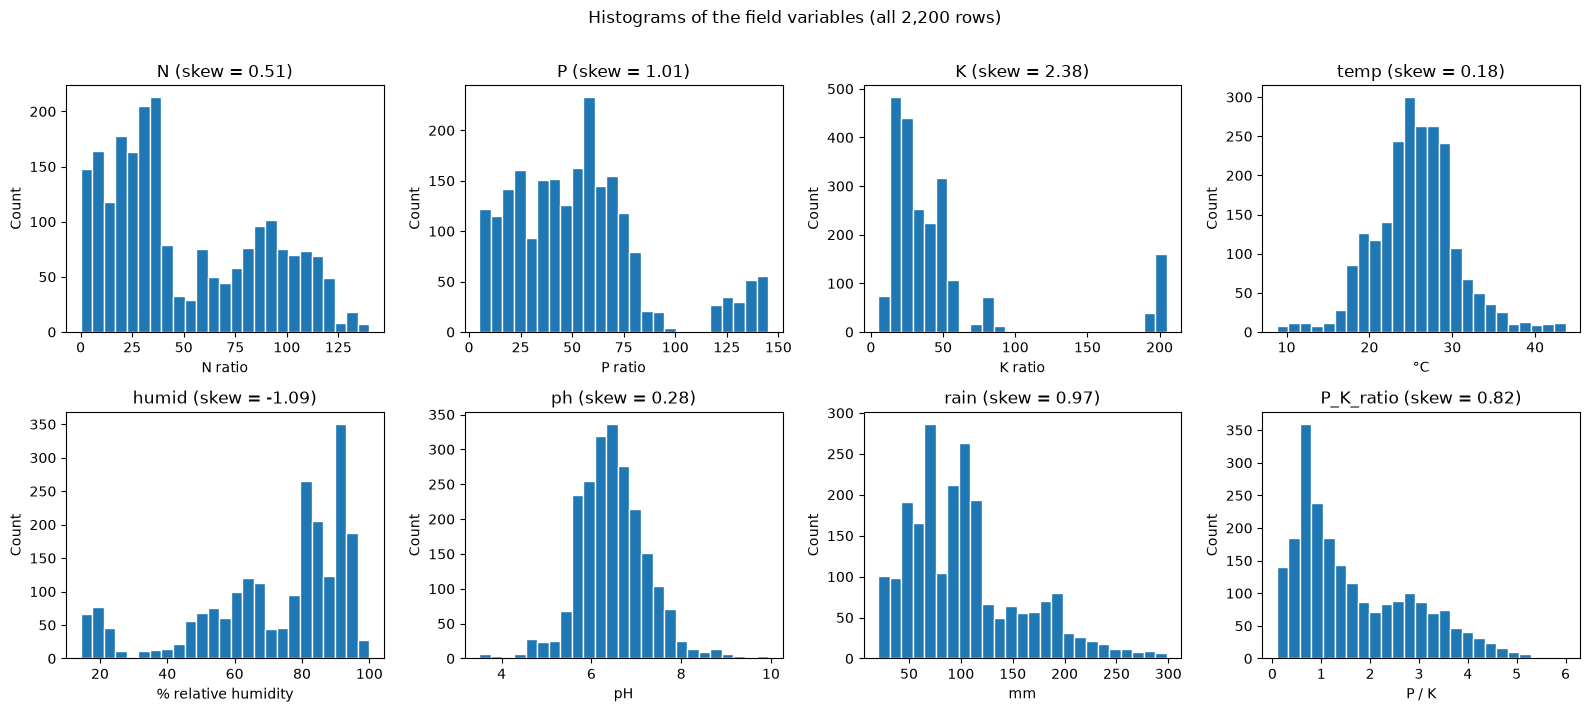

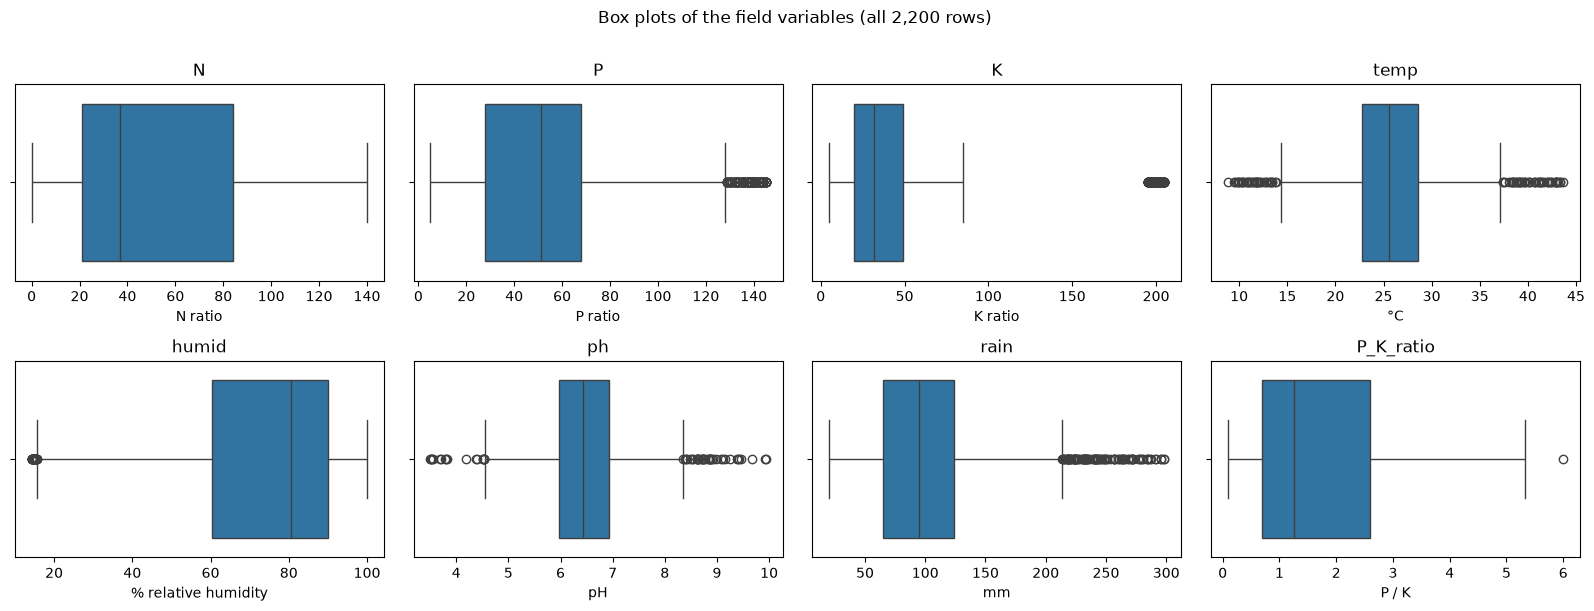

Skewness of row-level variables:
N            0.510000
P            1.011000
K            2.375000
temp         0.185000
humid       -1.092000
ph           0.284000
rain         0.966000
P_K_ratio    0.824000
dtype: float64


In [11]:
row_level = ["N", "P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"]
row_level = [c for c in row_level if c in df]

display(df[row_level].describe())

UNITS = {"N": "N ratio", "P": "P ratio", "K": "K ratio", "temp": "°C", "humid": "% relative humidity",
         "ph": "pH", "rain": "mm", "P_K_ratio": "P / K"}

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), row_level):
    ax.hist(df[col], bins=25, edgecolor="white")
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(UNITS.get(col, col)); ax.set_ylabel("Count")
for ax in axes.flatten()[len(row_level):]:
    ax.axis("off")
fig.suptitle("Histograms of the field variables (all 2,200 rows)", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flatten(), row_level):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col); ax.set_xlabel(UNITS.get(col, col))
for ax in axes.flatten()[len(row_level):]:
    ax.axis("off")
fig.suptitle("Box plots of the field variables (all 2,200 rows)", y=1.01)
plt.tight_layout()
plt.show()

print("Skewness of row-level variables:")
print(df[row_level].skew().round(3))

### 2.7 Transformations

We use the two transformations :

* **Box-Cox** finds the power λ that makes a strictly positive variable closest to normal; we report the nearest rung of **Tukey's ladder** (2 = square, 1 = none, 0.5 = square root, 0 = log, −1 = reciprocal) so the choice is easy to explain.
* Rule: transform a **strictly positive continuous predictor** when |skewness| > 0.75.
* `ca_area_ha` and `ca_farm_value` are mostly zeros (crops not grown in Canada), so Box-Cox is impossible; we use **log(x + 1)**, the log rung of Tukey's ladder shifted by 1 so that 0 stays 0.
* The response `N` is **not** transformed so its coefficients stay in the original units (and N contains zeros, so Box-Cox cannot be applied).

New columns get a `_bc` (Box-Cox) or `_log` suffix; the originals are kept for reference but **only one version of each variable** is offered to the models.

,variable,skew_before,lambda,nearest_tukey_rung,skew_after
0,P,1.011000,0.391000,0.5 (square root),-0.030000
1,K,2.375000,-0.335000,-0.5 (reciprocal square root),-0.030000
2,temp,0.185000,NaN,not transformed,0.185000
3,humid,-1.092000,2.118000,2 (square),-0.472000
4,ph,0.284000,NaN,not transformed,0.284000
5,rain,0.966000,0.217000,0 (log),-0.014000
6,P_K_ratio,0.824000,0.247000,0 (log),-0.052000


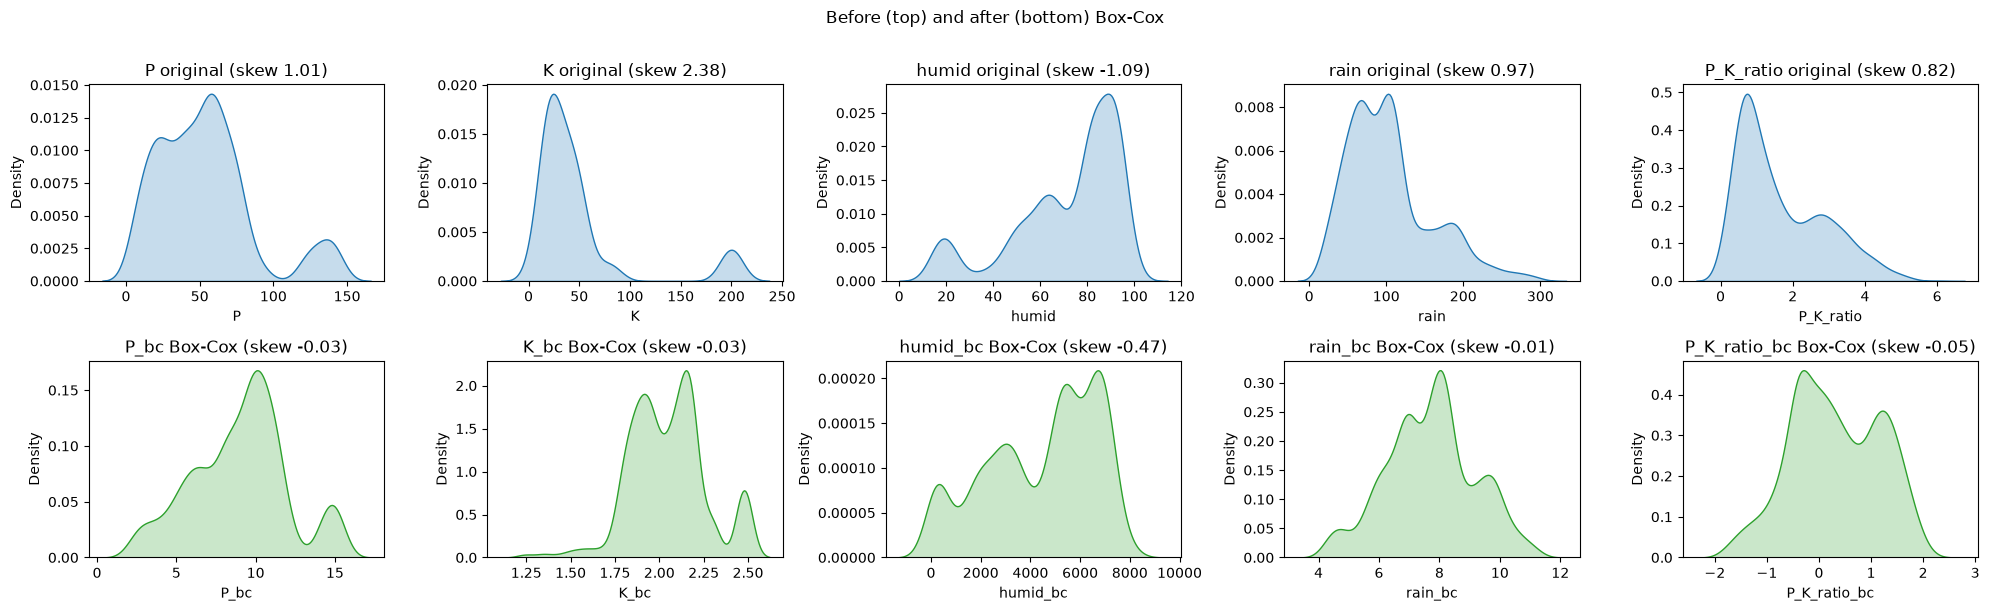

In [12]:

TUKEY = {2: "square", 1: "none", 0.5: "square root", 0: "log", -0.5: "reciprocal square root",
         -1: "reciprocal", -2: "reciprocal square"}

candidates = [c for c in ["P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"] if c in df]
transform_log = []
use_version = {}     # variable -> column that the models should use

for c in candidates:
    skew = df[c].skew()
    if abs(skew) > 0.75 and (df[c] > 0).all():
        transformed, lam = boxcox(df[c])
        df[c + "_bc"] = transformed
        rung = min(TUKEY, key=lambda p: abs(p - lam))
        transform_log.append({"variable": c, "skew_before": skew, "lambda": lam,
                              "nearest_tukey_rung": f"{rung} ({TUKEY[rung]})",
                              "skew_after": pd.Series(transformed).skew()})
        use_version[c] = c + "_bc"
    else:
        transform_log.append({"variable": c, "skew_before": skew, "lambda": np.nan,
                              "nearest_tukey_rung": "not transformed", "skew_after": skew})
        use_version[c] = c

for c in ["ca_area_ha", "ca_farm_value"]:
    df[c + "_log"] = np.log1p(df[c])
    use_version[c] = c + "_log"

display(pd.DataFrame(transform_log).round(3))

bc_cols = [v for v in use_version.values() if v.endswith("_bc")]
if bc_cols:
    fig, axes = plt.subplots(2, len(bc_cols), figsize=(4 * len(bc_cols), 6), squeeze=False)
    for i, c in enumerate(bc_cols):
        orig = c.replace("_bc", "")
        sns.kdeplot(df[orig], fill=True, ax=axes[0, i])
        axes[0, i].set_title(f"{orig} original (skew {df[orig].skew():.2f})")
        sns.kdeplot(df[c], fill=True, ax=axes[1, i], color="tab:green")
        axes[1, i].set_title(f"{c} Box-Cox (skew {df[c].skew():.2f})")
    fig.suptitle("Before (top) and after (bottom) Box-Cox", y=1.01)
    plt.tight_layout()
    plt.show()

### 2.8 Converting categorical variables

* **Nominal** variables (`label`, `life_form`, `eco_category`) → dummy (indicator) variables with **k − 1** columns (`drop_first=True`). Dropping one level avoids perfect collinearity with the intercept (the dummies for all k levels always add up to 1).
* **Ordinal** `ph_class` → ordered codes 0 = acidic, 1 = neutral, 2 = alkaline, so the order is kept in a single column.
* Binary flags (`is_legume`, `grown_in_canada`) are already 0/1.

The original text columns are kept as pandas `category` types so the train/test comparison (chi-square) can use them.

In [13]:
nominal = [c for c in ["label", "life_form", "eco_category"] if c in df]
for c in nominal:
    df[c] = df[c].astype("category")

df["ph_class_ord"] = df["ph_class"].cat.codes          # 0 acidic, 1 neutral, 2 alkaline

def clean(name):
    return re.sub(r"[^0-9a-zA-Z_]", "_", name)

dummies = pd.get_dummies(df[nominal], prefix=nominal, drop_first=True, dtype=int)
dummies.columns = [clean(c) for c in dummies.columns]
df = pd.concat([df, dummies], axis=1)

label_dummies = [c for c in dummies.columns if c.startswith("label_")]
other_dummies = [c for c in dummies.columns if not c.startswith("label_")]
print(f"{len(label_dummies)} label dummies, {len(other_dummies)} life-form/category dummies")
print(other_dummies)

21 label dummies, 0 life-form/category dummies
[]


### 2.9 Final study file

`study` holds the usable variables (one version of each transformed variable, all categoricals converted). It is saved to `crop_study_file.csv`.

In [14]:
binary_flags = [c for c in ["is_legume", "grown_in_canada"] if c in df]
eco_numeric_cols = [c for c in df.columns if c.startswith("eco_") and pd.api.types.is_numeric_dtype(df[c])
                    and c not in dummies.columns]

# Order matters for the collinearity check in section 6: is_legume is listed before the
# category dummies, so if a "pulses" dummy duplicates it, the dummy is the one removed.
row_level_vars = ["N"] + [use_version[c] for c in ["P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"]] \
                 + ["ph_class_ord"]
crop_level_vars = eco_numeric_cols + [use_version["ca_area_ha"], use_version["ca_farm_value"]] \
                  + binary_flags + other_dummies

study_cols = list(dict.fromkeys(row_level_vars + crop_level_vars + label_dummies))
study = df[study_cols].copy()
study.to_csv("crop_study_file.csv", index=False)

n_vars_before_dummies = len(row_level_vars) + len(eco_numeric_cols) + 2 + len(binary_flags) + len(nominal)
print(f"Usable variables before dummy coding : {n_vars_before_dummies}")
print(f"Usable columns in study file          : {study.shape[1]}")
assert study.shape[1] >= 25, "Study file must contain at least 25 usable variables"
print("Missing values in study file:", int(study.isna().sum().sum()))
study.info()

Usable variables before dummy coding : 29
Usable columns in study file          : 49
Missing values in study file: 0
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 49 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   N                  2200 non-null   int64  
 1   P_bc               2200 non-null   float64
 2   K_bc               2200 non-null   float64
 3   temp               2200 non-null   float64
 4   humid_bc           2200 non-null   float64
 5   ph                 2200 non-null   float64
 6   rain_bc            2200 non-null   float64
 7   P_K_ratio_bc       2200 non-null   float64
 8   ph_class_ord       2200 non-null   int8   
 9   eco_topt_min       2200 non-null   float64
 10  eco_topt_max       2200 non-null   float64
 11  eco_tabs_min       2200 non-null   float64
 12  eco_tabs_max       2200 non-null   float64
 13  eco_ropt_min       2200 non-null   float64
 14  eco_ropt_max  

### 2.10 Data sources, rationale and transformations

**Why augment at crop level.** Our Crop Recommendation dataset has no location or date column; the only key that links it to other data is the crop name (`label`). We therefore chose sources that describe *crops*, joined many-to-one on `label`.

**FAO EcoCrop.** Developed by the Food and Agriculture Organization of the UN, EcoCrop records the optimal and absolute temperature, rainfall and soil-pH limits, crop-cycle length, life form and category for thousands of plant species. It is authoritative, global (not tied to any one country) and directly answers the question our project asks: *are these conditions right for this crop?* We matched crops by scientific name to avoid ambiguity (e.g., "gram", "melon").

**Statistics Canada (tables 32-10-0359-01, 32-10-0364-01, 32-10-0365-01).** These official tables give harvested/cultivated area and farm value by crop. They let us ask how relevant each crop is to Canadian agriculture. Most of our 22 crops are tropical and are not grown commercially in Canada; for those, 0 hectares and $0 are true values rather than missing data, so we can use the whole table without imputation. We average the latest five years to smooth out single-year weather effects.

**Domain-knowledge variable.** `is_legume` comes from botany (family Fabaceae). Legumes host nitrogen-fixing bacteria, which is directly relevant to our dependent variable, soil nitrogen.

**Transformations.**
* Box-Cox / Tukey's ladder was applied to strictly positive, clearly skewed predictors (rule: |skew| > 0.75). The table above shows λ, the nearest Tukey rung and the skewness before and after. As the slides note, simple prediction works best with variables that are close to normally distributed and linearly related; reducing skew moves the variables in that direction and reduces the pull of extreme values.
* log(x + 1) was used for the zero-heavy Canadian area and value variables because Box-Cox requires positive values.
* Categorical variables were dummy coded (k − 1) and `ph_class` was ordinal-coded, as described in 2.8.
* Any EcoCrop field missing for one of our crops was dropped rather than filled, so no values are estimated.

**Caveat we keep in mind for modelling.** Every crop-level variable has only 22 distinct values (one per crop). They are therefore perfectly explained by the `label` dummies, so the two groups must **not** be used in the same regression model. The regression sections use the crop-level variables (they describe *why* crops differ); the `label` dummies remain in the study file for other parts of the project.

## 3. Split into Training and Test Sets

As in the class demo we use an **80/20 random split** with a fixed seed. The training set is used to build every model; the test set is only used to validate them.